# Chapter 3: Unsupervised Learning and Preprocessing

## Chapter Summary
Unsupervised learning works without target labels. This chapter covers scaling, PCA, NMF, t-SNE, and clustering with k-means, agglomerative clustering, and DBSCAN. Labels are used only after fitting to evaluate how discovered structure relates to known classes.

## Theoretical Deep-Dive

Scaling prevents large-unit features from dominating distance and variance. Standardization applies $z=(x-\mu)/\sigma$, with parameters learned from training data only.

PCA finds orthogonal directions of maximum variance and projects data onto them. NMF approximates a nonnegative matrix as $X \approx WH$, producing additive parts. t-SNE preserves local neighborhoods for visualization but should not be treated as a predictive transform.

Clustering methods encode different assumptions: k-means favors compact spherical clusters, hierarchical clustering builds nested merges, and DBSCAN identifies dense regions plus noise without specifying the number of clusters.

**Book coverage:** preprocessing, PCA, NMF, t-SNE, clustering, and cluster evaluation (Chapter 3, printed pp. 131-208).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer, load_digits, make_blobs
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.svm import SVC

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=42
)
results = []
for scaler in [StandardScaler(), MinMaxScaler(), RobustScaler()]:
    Xtr = scaler.fit_transform(X_train)
    Xte = scaler.transform(X_test)
    model = SVC(C=2).fit(Xtr, y_train)
    results.append((scaler.__class__.__name__, model.score(Xte, y_test)))
display(pd.DataFrame(results, columns=["preprocessing", "test_accuracy"]).round(3))

,preprocessing,test_accuracy
0,StandardScaler,0.986
1,MinMaxScaler,0.986
2,RobustScaler,0.986


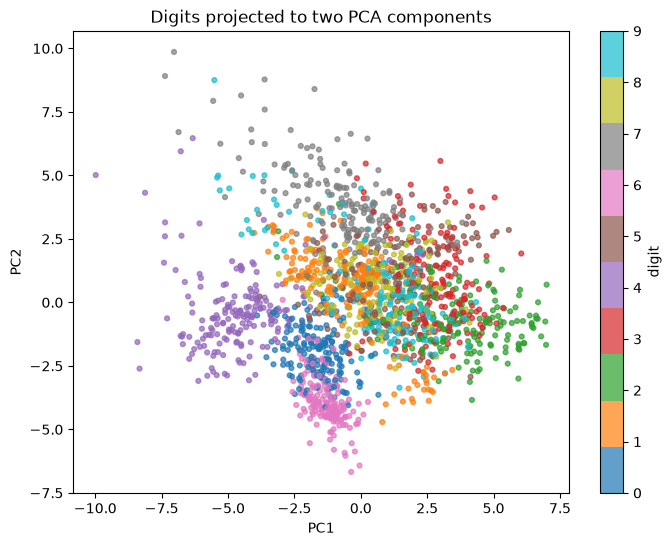

Explained variance ratio: [0.12  0.096]


NMF factor shapes: (1797, 10) (10, 64)


In [2]:
from sklearn.decomposition import PCA, NMF

digits = load_digits()
X_scaled = StandardScaler().fit_transform(digits.data)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(8, 6))
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=digits.target, cmap="tab10", s=12, alpha=0.7)
ax.set(title="Digits projected to two PCA components", xlabel="PC1", ylabel="PC2")
plt.colorbar(scatter, ax=ax, label="digit"); plt.show()
print("Explained variance ratio:", pca.explained_variance_ratio_.round(3))

nmf = NMF(n_components=10, init="nndsvda", max_iter=800, random_state=42)
W = nmf.fit_transform(digits.data)
print("NMF factor shapes:", W.shape, nmf.components_.shape)

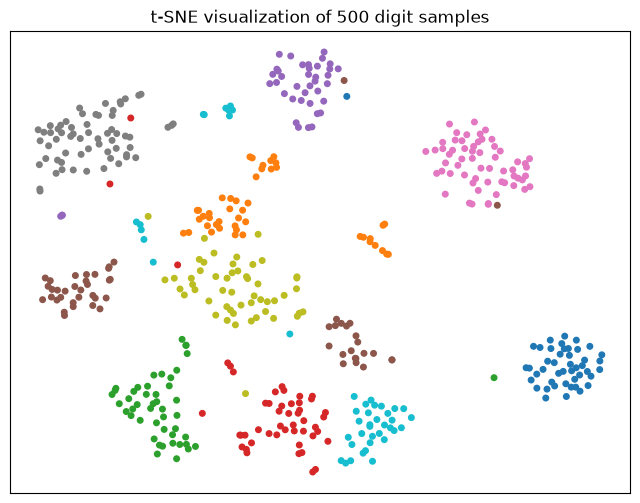

In [3]:
from sklearn.manifold import TSNE

subset = np.random.default_rng(42).choice(len(digits.data), size=500, replace=False)
embedding = TSNE(n_components=2, init="pca", learning_rate="auto", max_iter=750, random_state=42).fit_transform(digits.data[subset])
plt.figure(figsize=(8, 6))
plt.scatter(embedding[:, 0], embedding[:, 1], c=digits.target[subset], cmap="tab10", s=16)
plt.title("t-SNE visualization of 500 digit samples")
plt.xticks([]); plt.yticks([]); plt.show()

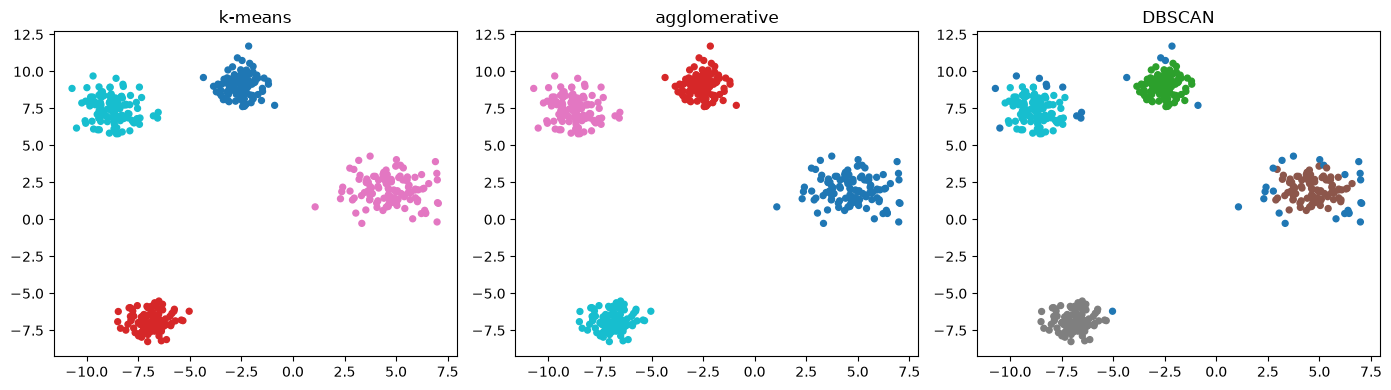

,method,ARI,silhouette,noise_points
0,k-means,1.000,0.829,0
1,agglomerative,1.000,0.829,0
2,DBSCAN,0.882,0.700,40


In [4]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import adjusted_rand_score, silhouette_score

X_blob, y_blob = make_blobs(n_samples=450, centers=4, cluster_std=[0.7, 1.1, 0.6, 0.9], random_state=42)
clusterers = {
    "k-means": KMeans(n_clusters=4, n_init=20, random_state=42),
    "agglomerative": AgglomerativeClustering(n_clusters=4),
    "DBSCAN": DBSCAN(eps=0.6, min_samples=6),
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
scores = []
for ax, (name, clusterer) in zip(axes, clusterers.items()):
    labels = clusterer.fit_predict(X_blob)
    valid = len(set(labels)) > 1
    scores.append((name, adjusted_rand_score(y_blob, labels), silhouette_score(X_blob, labels) if valid else np.nan, int((labels == -1).sum())))
    ax.scatter(X_blob[:, 0], X_blob[:, 1], c=labels, cmap="tab10", s=18)
    ax.set_title(name)
plt.tight_layout(); plt.show()
display(pd.DataFrame(scores, columns=["method", "ARI", "silhouette", "noise_points"]).round(3))

## Key Takeaways
- Fit preprocessing only on training data, then reuse it on validation/test data.
- PCA is a linear variance-preserving projection; NMF learns additive nonnegative parts.
- t-SNE is primarily an exploratory visualization tool.
- Clustering has no universally correct algorithm; the geometry and density assumptions matter.
- Evaluate clusters with internal metrics and, when legitimate labels exist, external metrics such as ARI.